# Part 3: Seam Finding

## 3.1 Finding and Removing Seams

In [2]:
import os
import sys
from pathlib import Path
import numpy as np
STARTER = Path("starter_pack")
sys.path.insert(0, str(STARTER / "code"))
from utils import load_image, show

IMG_ROOT = STARTER / "images"
from seam_carving import reduce_img_size, compute_energy_from_gradient
from PIL import Image

In [3]:
tower = load_image(IMG_ROOT / "part3_seams" / "broadway_tower.png", gray=False)
print(tower.shape[:2])


(484, 714)


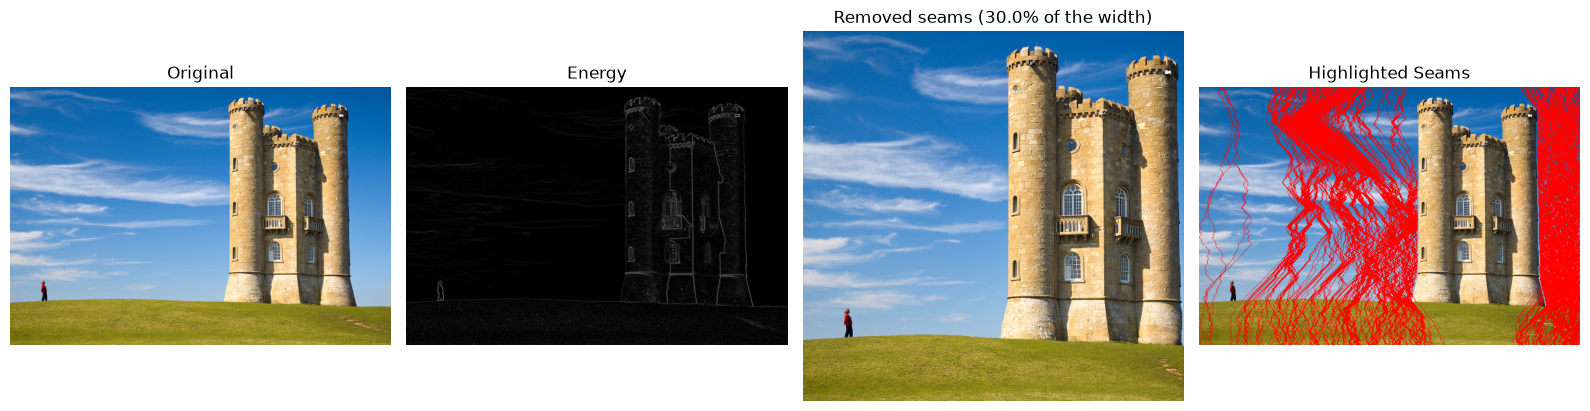

In [4]:
tower_energy = compute_energy_from_gradient(tower)
ratio = 0.3
tower_seam, tower_highlight = reduce_img_size(img=tower,target_width_ratio=ratio)
show(tower,tower_energy,tower_seam,tower_highlight,titles=["Original","Energy",f"Removed seams ({ratio * 100}% of the width)","Highlighted Seams"])

## 3.2 Results and Comparisons

In [5]:
img_dir= IMG_ROOT / "part3_seams"

broadway_tower.png


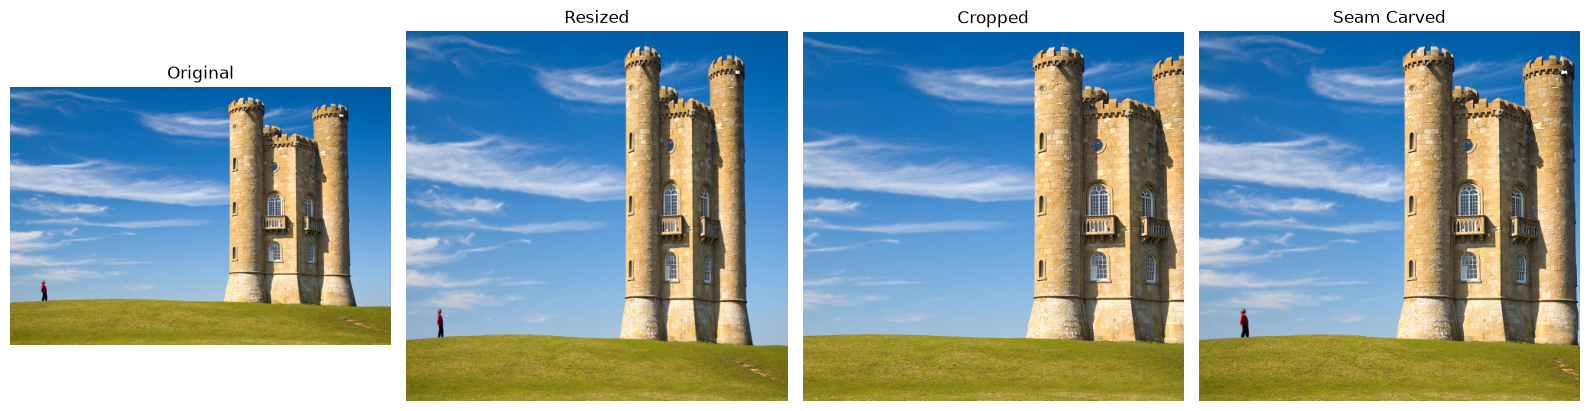

home.jpg


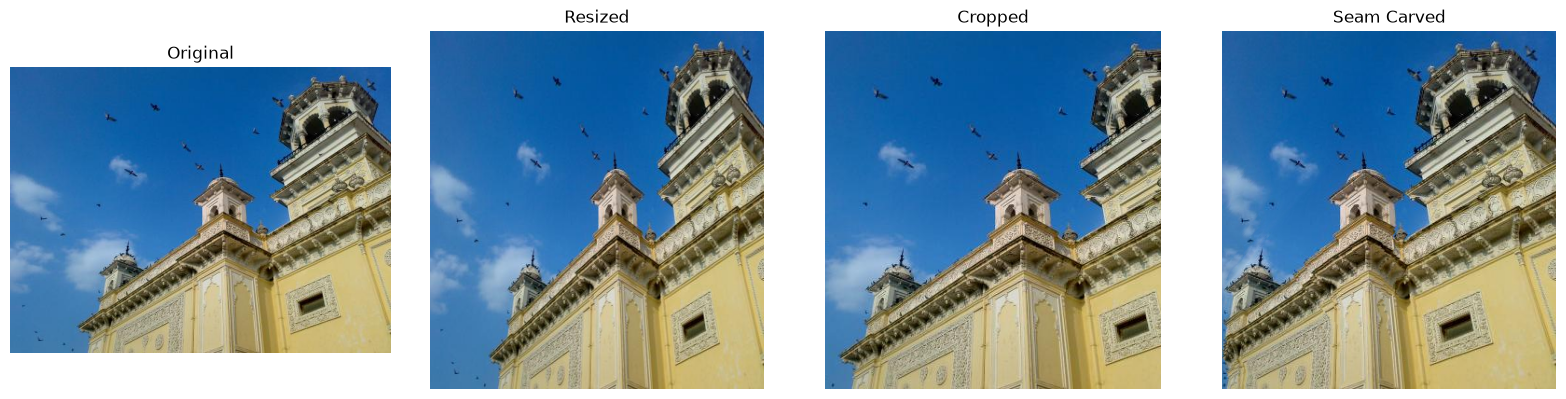

rocket.jpg


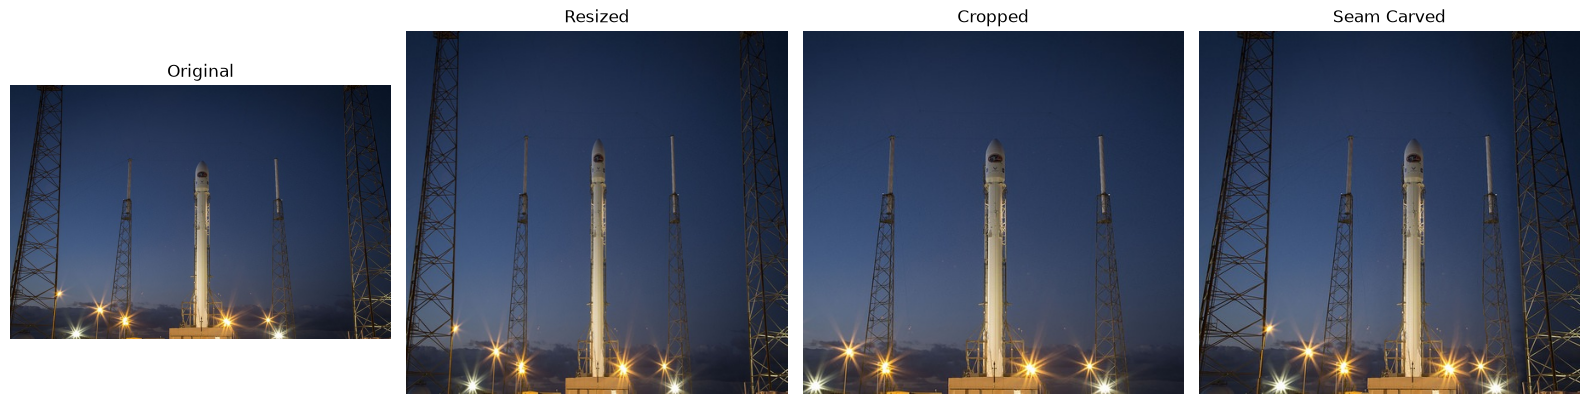

starry_night.jpg


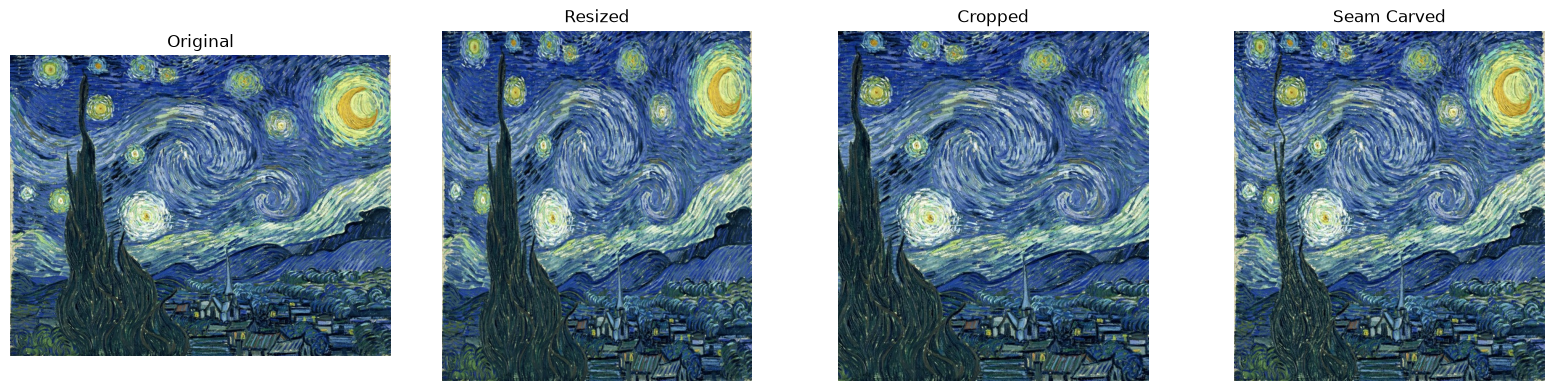

In [8]:
for img_path in os.listdir(img_dir):
    if not img_path.lower().endswith((".png", ".jpg", ".jpeg")):
        continue
    print(img_path)

    img = load_image(img_dir / img_path, gray=False)
    h, w = img.shape[:2]
    ratio = 0.3
    new_w = int((1 - ratio) * w)
    crop_val = int(ratio * w) // 2

    is_float = img.dtype.kind == "f"
    img_u8 = (img * 255).round().astype(np.uint8) if is_float else img
    img_pil = Image.fromarray(img_u8)

    resized = np.array(img_pil.resize((new_w, h)))
    cropped = np.array(img_pil.crop((crop_val, 0, w - crop_val, h)))

    if is_float:
        resized = resized.astype(img.dtype) / 255.0
        cropped = cropped.astype(img.dtype) / 255.0

    seam_carved, _ = reduce_img_size(img, target_width_ratio=ratio)

    show(img, resized, cropped, seam_carved,
         titles=["Original", "Resized", "Cropped", "Seam Carved"])